# 1. Is the size formula the real file size?

Papers usually estimate a compressed model's size as **number of weights × bits per weight ÷ 8**.
A real file also stores **scales** (the numbers that turn rounded codes back into weights) and keeps a few
layers at 16 bits. This notebook compares the formula with real files written to disk.

Everything here runs on a laptop in under a minute.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # run from the repository root
sys.path.insert(0, "src")
import numpy as np
from IPython.display import Image, display

import ast
def show(path, *names):
    """Print the real source of functions/classes from a file in src/ (read directly, never copied)."""
    src = open(path).read(); lines = src.splitlines(); tree = ast.parse(src)
    nodes = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
    for name in names:
        n = nodes[name]; start = n.decorator_list[0].lineno if n.decorator_list else n.lineno
        print(f"# ---- {path}, lines {start}-{n.end_lineno}")
        print("\n".join(lines[start - 1:n.end_lineno])); print()

def show_lines(path, start_text, end_text):
    """Print a block of a script, from the line containing start_text to the line containing end_text."""
    lines = open(path).read().splitlines()
    i = next(k for k, l in enumerate(lines) if start_text in l)
    j = next(k for k, l in enumerate(lines[i + 1:], i + 1) if end_text in l)
    print(f"# ---- {path}, lines {i + 1}-{j + 1}"); print("\n".join(lines[i:j + 1]))

## 1.1 DeiT-Small: formula against the real file

The real files were written by `src/phase1_audit.py` and measured with `os.path.getsize()`.
Group size = how many weights share one scale (here 256).

In [2]:
audit = json.load(open("evidence/audit_deit/audit.json"))["sections"]["sizes"]
N = 22_050_664                                   # weights in DeiT-Small
print(f"{'format':<6}{'group':>7}{'formula MB':>12}{'real MB':>10}{'real is bigger by':>20}")
for r in audit:
    if r["format"].startswith("INT") and r["group"] == "g=256":
        bits = int(r["format"][3:])
        formula = N * bits / 8 / 1e6
        real = r["bytes"] / 1e6
        print(f"{r['format']:<6}{r['group']:>7}{formula:>12.2f}{real:>10.2f}{100*(real/formula-1):>19.1f}%")

format  group  formula MB   real MB   real is bigger by
INT8    g=256       22.05     23.04                4.5%
INT4    g=256       11.03     12.42               12.7%
INT3    g=256        8.27      9.77               18.1%
INT2    g=256        5.51      7.12               29.1%


**Reading it:** at 8 bits the formula is close (+4.5%). At 2 bits the real file is 29.1% bigger, because the
scales and 16-bit layers do not shrink when the bits do. At 4 bits the real file is 12.42 MB, which is over the
10 MB limit, so a 4-bit route must also prune.

### The code that writes a real file

`quantize_groupwise` rounds each group of weights to whole-number codes and one 16-bit scale.
`serialize_quantized` writes the codes, the scales and the 16-bit layers into one binary file, which is then
measured on disk.

In [3]:
show("src/phase1_audit.py", "quantize_groupwise", "pack_codes", "serialize_quantized")

# ---- src/phase1_audit.py, lines 95-120
def quantize_groupwise(w: torch.Tensor, bits: int, group_size: int):
    """
    Symmetric group-wise quantization, the AWQ/GPTQ-style layout.

    Returns (codes, scales, max_abs_err). Codes are unsigned ints in
    [0, 2**bits - 1]; one FP16 scale per group, written to the file --
    a quantized model without its scales is not a model.
    """
    flat = w.detach().float().reshape(-1)
    n = flat.numel()
    g = min(group_size, n)
    pad = (-n) % g
    if pad:
        flat = torch.cat([flat, torch.zeros(pad)])
    groups = flat.reshape(-1, g)

    qmax = 2 ** (bits - 1) - 1                 # symmetric signed range
    scale = groups.abs().amax(dim=1, keepdim=True) / qmax
    scale = torch.where(scale == 0, torch.ones_like(scale), scale)
    scale = scale.half().float()               # scales are stored as FP16

    q = torch.clamp(torch.round(groups / scale), -qmax - 1, qmax)
    err = (q * scale - groups).abs().max().item()

    codes = (q

## 1.2 Second check: rebuild every size from the network's shape

For five different networks, `src/arch_audit_summary.py` predicts each file's size from the layer shapes alone
(codes + one 2-byte scale per group + 16-bit layers) and asserts that the measured file differs from the
prediction only by the file header. If any file disagreed, this cell would stop with an error.

In [4]:
show("src/arch_audit_summary.py", "predicted_bytes")

# ---- src/arch_audit_summary.py, lines 25-36
def predicted_bytes(state, bits, g):
    tot = 0
    for name, t in state.items():
        n = t.numel()
        q = t.dim() >= 2 and name.endswith("weight") and not (
            name.startswith("patch_embed") or name.startswith("head"))
        if q:
            gg = min(g, n)
            tot += math.ceil(n * bits / 8) + math.ceil(n / gg) * 2
        else:
            tot += n * 2
    return tot



In [5]:
import subprocess, glob
out = subprocess.run([sys.executable, "src/arch_audit_summary.py", *sorted(glob.glob("evidence/audit_multiarch/*.json"))],
                     capture_output=True, text=True, check=True).stdout
print(out)

MEASURED file size vs the nominal formula params x bits / 8   (standard policy:
patch_embed + head + norms + biases FP16; symmetric group-wise, FP16 scales)

model                               params  width FP16 share  INT8 g256  INT4 g256  INT3 g256  INT2 g256  INT4 g32  max hdr
deit_tiny_patch16_224            5,717,416    192      7.2%     +8.0%     +23.2%     +33.3%     +53.5%    +33.3%   6,992B
deit_small_patch16_224          22,050,664    384      3.7%     +4.5%     +12.7%     +18.1%     +29.1%    +23.2%   7,101B
swin_tiny_patch4_window7_224    28,288,354     96      3.0%     +3.8%     +10.7%     +15.3%     +24.5%    +21.3%   9,765B
deit_base_patch16_224           86,567,656    768      1.9%     +2.7%      +7.2%     +10.2%     +16.3%    +17.9%   7,263B
vit_large_patch16_224          304,326,632   1024      0.8%     +1.5%      +3.9%      +5.4%      +8.5%    +14.7%  14,626B

Every measured file = predicted-from-shapes + a JSON header (last column, worst case);
the assert above fai

**Reading it:** the smaller the network, the bigger the gap (DeiT-Tiny +53.5% at 2 bits, ViT-Large +8.5%),
because the layers kept at 16 bits are a larger share of a small network.

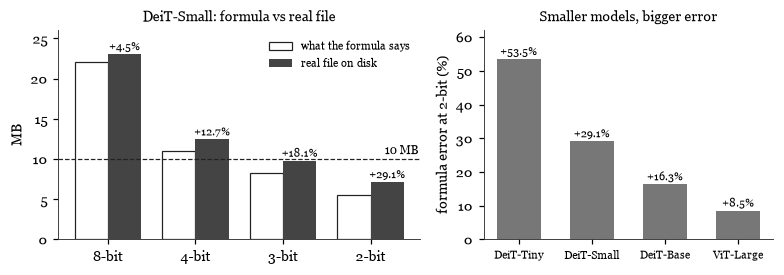

In [6]:
display(Image("proposal/figs/png/fig1_size_gap.png", width=760))

## 1.3 Example: a published size, rebuilt

Mix-QViT reports "11.4 MB" for 4-bit DeiT-Small. Rebuilt with the formula (blocks at 4 bits, first and last
layer at 8 bits), it comes out at 11.3–11.4 MB, so it was computed, not measured. Built their way (one scale per
row), a real file is only 2–5% larger, so the formula is a fair shortcut for them. It stops being fair under a
hard 10 MB limit, where small groups are needed.

In [7]:
import timm
m = timm.create_model("deit_small_patch16_224", pretrained=False)
P = dict(m.named_parameters())
block = sum(v.numel() for k, v in P.items() if k.startswith("blocks") and k.endswith("weight") and v.dim() == 2)
pe, hd = P["patch_embed.proj.weight"].numel(), P["head.weight"].numel()
print(f"formula, blocks 4-bit + patch/head 8-bit: {(block*4/8 + pe + hd)/1e6:.2f} MB   (Mix-QViT prints 11.4)")

formula, blocks 4-bit + patch/head 8-bit: 11.30 MB   (Mix-QViT prints 11.4)
